In [1]:
import os
print("Notebook runs from:", os.getcwd())
print("Dataset found:", os.path.exists("../data/Dataset.csv"))

Notebook runs from: d:\Audience Rating Classifier\notebooks
Dataset found: True


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Dataset.csv")
df = df.drop_duplicates(subset=["title", "type", "release_year"])
df = df.replace("Not Given", np.nan)
print(df.shape)
df.head()

(8787, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
def save_table(table, filename, title=""):
    fig, ax = plt.subplots(figsize=(6, 0.8 + 0.4 * len(table)))
    ax.axis("off")
    t = ax.table(cellText=table.values, colLabels=table.columns,
                 rowLabels=table.index, loc="center")
    t.scale(1, 1.4)
    ax.set_title(title)
    plt.savefig(f"../screenshots/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

def save_fig(filename):
    plt.savefig(f"../screenshots/{filename}", dpi=150, bbox_inches="tight")

rating
TV-MA       3205
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


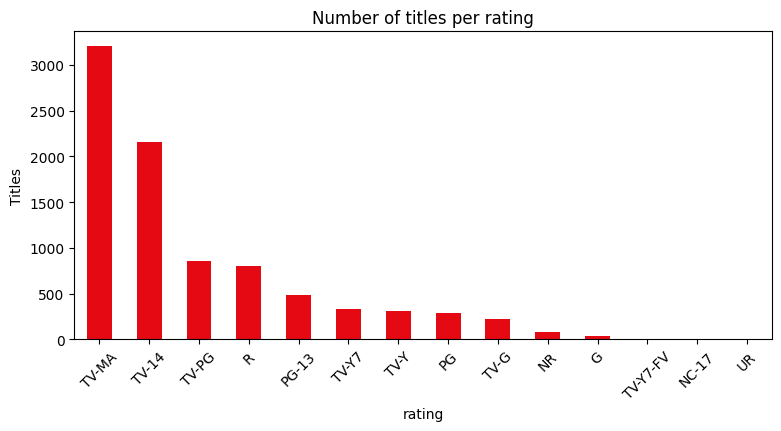

In [4]:
counts = df["rating"].value_counts()
print(counts)

counts.plot(kind="bar", figsize=(9, 4), color="#E50914")
plt.title("Number of titles per rating")
plt.ylabel("Titles")
plt.xticks(rotation=45)
save_fig("01_rating_counts.png")
plt.show()

In [5]:
print(pd.crosstab(df["rating"], df["type"]))

type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           796        2
TV-14      1426      729
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


Titles with no group (NR and UR): 82
Titles kept: 8705
audience
Adults    4006
Teens     2645
Family    1148
Kids       906
Name: count, dtype: int64
audience
Adults    0.460
Teens     0.304
Family    0.132
Kids      0.104
Name: count, dtype: float64


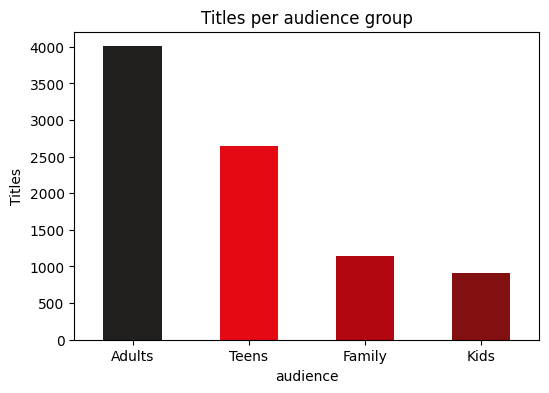

In [6]:
groups = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Family", "PG": "Family",
    "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
}

df["audience"] = df["rating"].map(groups)
print("Titles with no group (NR and UR):", df["audience"].isna().sum())

df = df.dropna(subset=["audience"])
print("Titles kept:", len(df))

aud = df["audience"].value_counts()
print(aud)
print((aud / aud.sum()).round(3))

aud.plot(kind="bar", color=["#221F1F", "#E50914", "#B20710", "#831010"], figsize=(6, 4))
plt.title("Titles per audience group")
plt.ylabel("Titles")
plt.xticks(rotation=0)
save_fig("02_audience_groups.png")
plt.show()

In [7]:
data = pd.DataFrame(index=df.index)

data["is_tv_show"] = (df["type"] == "TV Show").astype(int)
data["release_year"] = df["release_year"]

dates = pd.to_datetime(df["date_added"], errors="coerce")
data["year_added"] = dates.dt.year
data["month_added"] = dates.dt.month
data["year_added"] = data["year_added"].fillna(data["year_added"].median())
data["month_added"] = data["month_added"].fillna(data["month_added"].median())

data["has_director"] = df["director"].notna().astype(int)
data["duration_num"] = df["duration"].str.extract(r"(\d+)")[0].astype(int)

country = df["country"].fillna("Unknown").str.split(",").str[0].str.strip()
top = country.value_counts().head(10).index
data["country"] = country.where(country.isin(top), "Other")

print(data.shape)
print(data.isnull().sum())
data.head()

(8705, 7)
is_tv_show      0
release_year    0
year_added      0
month_added     0
has_director    0
duration_num    0
country         0
dtype: int64


,is_tv_show,release_year,year_added,month_added,has_director,duration_num,country
0,0,2020,2021,9,1,90,United States
1,1,2021,2021,9,1,1,France
2,1,2021,2021,9,1,1,United States
3,0,2021,2021,9,1,91,Other
4,0,1993,2021,9,1,125,United States


In [8]:
import re
from sklearn.feature_extraction.text import CountVectorizer

def clean_genres(text):
    parts = []
    for g in text.lower().split(","):
        g = re.sub(r"\b(tv|movies|shows)\b", "", g)
        g = re.sub(r"[^a-z ]", "", g)
        g = re.sub(r"\s+", "_", g.strip())
        if g:
            parts.append(g)
    return " ".join(parts)

df["genres_clean"] = df["listed_in"].apply(clean_genres)

cv = CountVectorizer(token_pattern=r"\S+", binary=True)
genre_matrix = cv.fit_transform(df["genres_clean"])
genre_df = pd.DataFrame(genre_matrix.toarray(),
                        columns=["genre_" + g for g in cv.get_feature_names_out()],
                        index=df.index)

print("Number of genre columns:", genre_df.shape[1])
df[["listed_in", "genres_clean"]].head(5)

Number of genre columns: 32


,listed_in,genres_clean
0,Documentaries,documentaries
1,"Crime TV Shows, International TV Shows, TV Act...",crime international action_adventure
2,"TV Dramas, TV Horror, TV Mysteries",dramas horror mysteries
3,"Children & Family Movies, Comedies",children_family comedies
4,"Dramas, Independent Movies, International Movies",dramas independent international


In [9]:
from sklearn.model_selection import train_test_split

X = pd.concat([pd.get_dummies(data, columns=["country"], dtype=int), genre_df], axis=1)
y = df["audience"]

print("X shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

X shape: (8705, 49)
Train size: 6964
Test size: 1741
audience
Adults    0.460
Teens     0.304
Family    0.132
Kids      0.104
Name: proportion, dtype: float64
audience
Adults    0.460
Teens     0.304
Family    0.132
Kids      0.104
Name: proportion, dtype: float64


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

rows = []

base_pred = ["Adults"] * len(y_test)
rows.append({
    "Model": "Baseline (always Adults)",
    "Accuracy": accuracy_score(y_test, base_pred),
    "Macro F1": f1_score(y_test, base_pred, average="macro", zero_division=0),
})

default_models = {
    "Decision Tree (default)": DecisionTreeClassifier(random_state=42),
    "Random Forest (default)": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in default_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Macro F1
0,Baseline (always Adults),0.460,0.158
1,Decision Tree (default),0.566,0.540
2,Random Forest (default),0.620,0.586


In [11]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_grid = {
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}

dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_grid, cv=cv5, scoring="f1_macro", n_jobs=-1
)
dt_search.fit(X_train, y_train)

print("Best settings:", dt_search.best_params_)
print("Best cross-validation macro F1:", round(dt_search.best_score_, 3))


Best settings: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20}
Best cross-validation macro F1: 0.596


In [12]:
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, None],
    "min_samples_leaf": [1, 3, 5],
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid, cv=cv5, scoring="f1_macro", n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Best settings:", rf_search.best_params_)
print("Best cross-validation macro F1:", round(rf_search.best_score_, 3))

Best settings: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}
Best cross-validation macro F1: 0.614


                      Model  Accuracy  Macro F1
0  Baseline (always Adults)     0.460     0.158
1   Decision Tree (default)     0.566     0.540
2   Random Forest (default)     0.620     0.586
3     Decision Tree (tuned)     0.619     0.592
4     Random Forest (tuned)     0.635     0.586


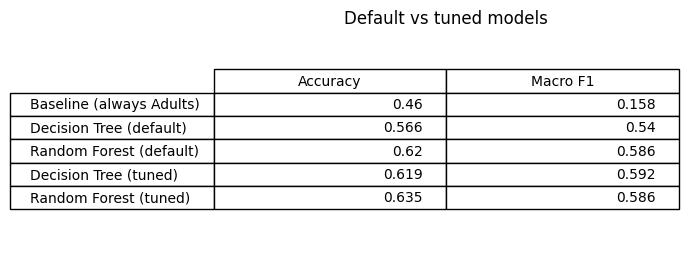

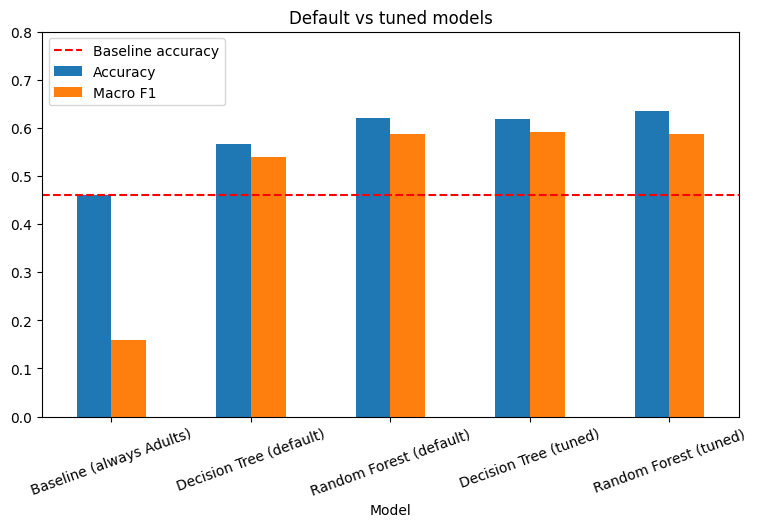

In [13]:
tuned = {
    "Decision Tree (tuned)": dt_search.best_estimator_,
    "Random Forest (tuned)": rf_search.best_estimator_,
}

for name, model in tuned.items():
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })

results = pd.DataFrame(rows).round(3)
print(results)
save_table(results.set_index("Model"), "03_model_comparison_table.png", "Default vs tuned models")

compare = results.set_index("Model")[["Accuracy", "Macro F1"]]
compare.plot(kind="bar", figsize=(9, 5), rot=20)
plt.axhline(results.loc[0, "Accuracy"], color="red", linestyle="--", label="Baseline accuracy")
plt.ylim(0, 0.8)
plt.title("Default vs tuned models")
plt.legend(loc="upper left")
save_fig("04_model_comparison.png")
plt.show()

                 Decision Tree Random Forest
criterion              entropy             -
max_depth                 None           nan
min_samples_leaf            20           3.0
n_estimators                 -         100.0


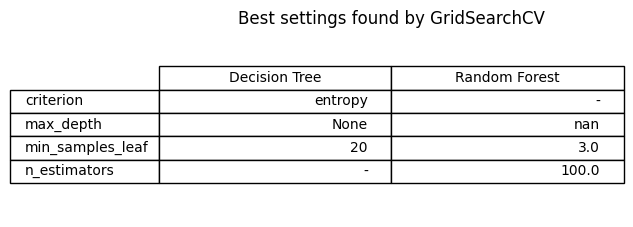

In [15]:
best = pd.DataFrame({
    "Decision Tree": pd.Series(dt_search.best_params_).astype(str),
    "Random Forest": pd.Series(rf_search.best_params_).astype(str),
}).fillna("-")
print(best)
save_table(best, "07_best_settings.png", "Best settings found by GridSearchCV")

              precision    recall  f1-score   support

        Kids      0.830     0.702     0.760       181
      Family      0.579     0.270     0.368       230
       Teens      0.552     0.420     0.477       529
      Adults      0.643     0.866     0.738       801

    accuracy                          0.635      1741
   macro avg      0.651     0.564     0.586      1741
weighted avg      0.627     0.635     0.612      1741



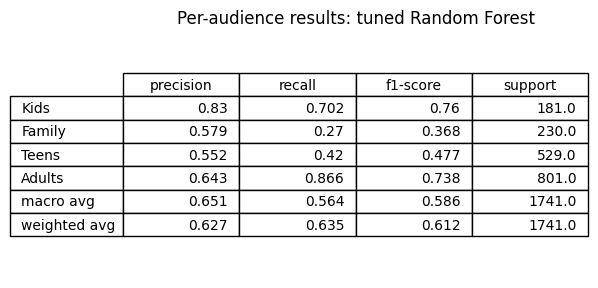

In [16]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

order = ["Kids", "Family", "Teens", "Adults"]

best_model = rf_search.best_estimator_
pred = best_model.predict(X_test)

print(classification_report(y_test, pred, labels=order, digits=3))

rep = classification_report(y_test, pred, labels=order, output_dict=True)
rep.pop("accuracy")
report_df = pd.DataFrame(rep).T.round(3)
report_df["support"] = report_df["support"].astype(int)
save_table(report_df, "08_classification_report.png", "Per-audience results: tuned Random Forest")

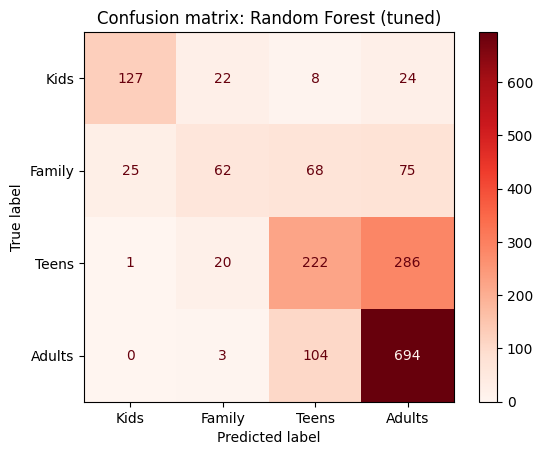

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=order, cmap="Reds")
plt.title("Confusion matrix: Random Forest (tuned)")
save_fig("05_confusion_matrix.png")
plt.show()

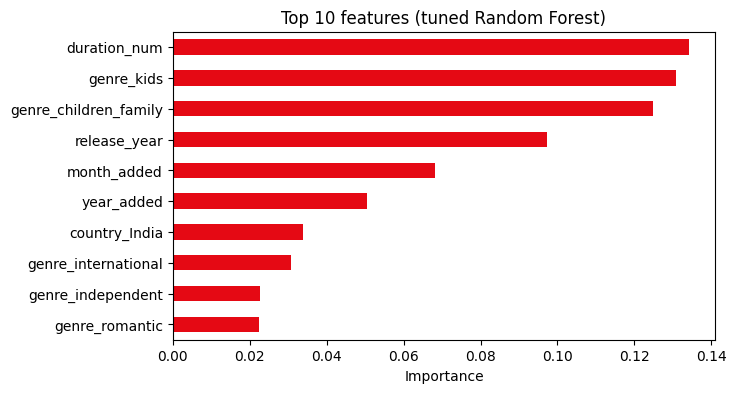

In [18]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values().tail(10)

imp.plot(kind="barh", figsize=(7, 4), color="#E50914")
plt.title("Top 10 features (tuned Random Forest)")
plt.xlabel("Importance")
save_fig("06_feature_importance.png")
plt.show()

                    Decision Tree    Random Forest
criterion                 entropy                -
max_depth         None (no limit)  None (no limit)
min_samples_leaf               20                3
n_estimators                    -              100


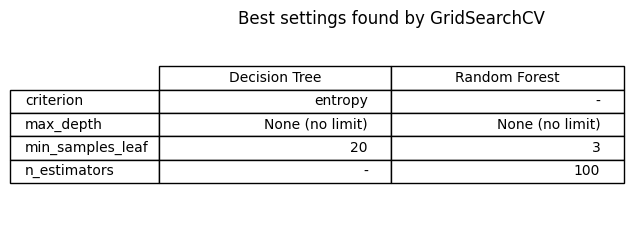

In [19]:
keys = ["criterion", "max_depth", "min_samples_leaf", "n_estimators"]

def show(params, key):
    if key not in params:
        return "-"
    value = params[key]
    return "None (no limit)" if value is None else str(value)

best = pd.DataFrame({
    "Decision Tree": [show(dt_search.best_params_, k) for k in keys],
    "Random Forest": [show(rf_search.best_params_, k) for k in keys],
}, index=keys)

print(best)
save_table(best, "07_best_settings.png", "Best settings found by GridSearchCV")